# Simple Non-Linear Model Using Keras Functional API 

In [1]:
from keras.models import Model
from keras.layers import *

In [2]:
x = Input(shape= (3,))

In [3]:
hidden1 = Dense(128 , activation = 'relu')(x)
hidden2 = Dense(64, activation='relu')(hidden1)

# Branching
output1 = Dense(1 , activation='linear')(hidden2)
output2 = Dense(1 , activation='sigmoid')(hidden2)

In [4]:
model = Model(inputs = x, outputs= [output1 , output2])

In [5]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 3)]          0           []                               
                                                                                                  
 dense (Dense)                  (None, 128)          512         ['input_1[0][0]']                
                                                                                                  
 dense_1 (Dense)                (None, 64)           8256        ['dense[0][0]']                  
                                                                                                  
 dense_2 (Dense)                (None, 1)            65          ['dense_1[0][0]']                
                                                                                              

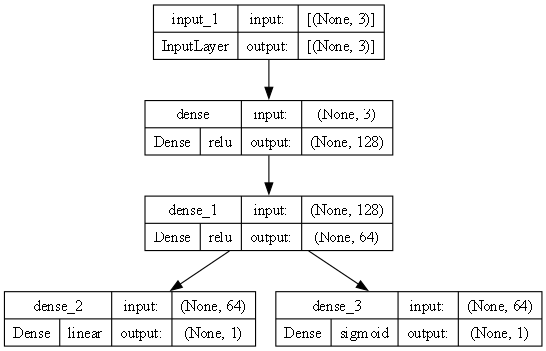

In [6]:
from keras.utils import plot_model
plot_model(model,show_shapes=True, show_layer_names=True, show_layer_activations=True, rankdir='TB', expand_nested=True, dpi = 80)

# Better Architecture - Have Multiple Inputs

In [7]:
import os
curr_dir = os.getcwd()
curr_dir

'd:\\Notes of CampusX\\dl'

In [8]:
# Inputs
input1 = Input(shape= (32,))
input2 = Input(shape= (128,))

# Branch 1
I1D1 = Dense(8, activation='relu')(input1)
I1D2 = Dense(4, activation='relu')(I1D1)

# Branch 2
I2D1 = Dense(64, activation='relu')(input2)
I2D2 = Dense(32, activation='relu')(I2D1)
I2D3 = Dense(4, activation='relu')(I2D2)

In [9]:
combine_branch = concatenate([I1D2, I2D3]) # Concatenate outputs of each branch

In [10]:
z = Dense(2, activation='relu')(combine_branch)
z1 = Dense(1, activation='sigmoid')(z)

In [11]:
model = Model(inputs=[input1, input2], outputs=z1)

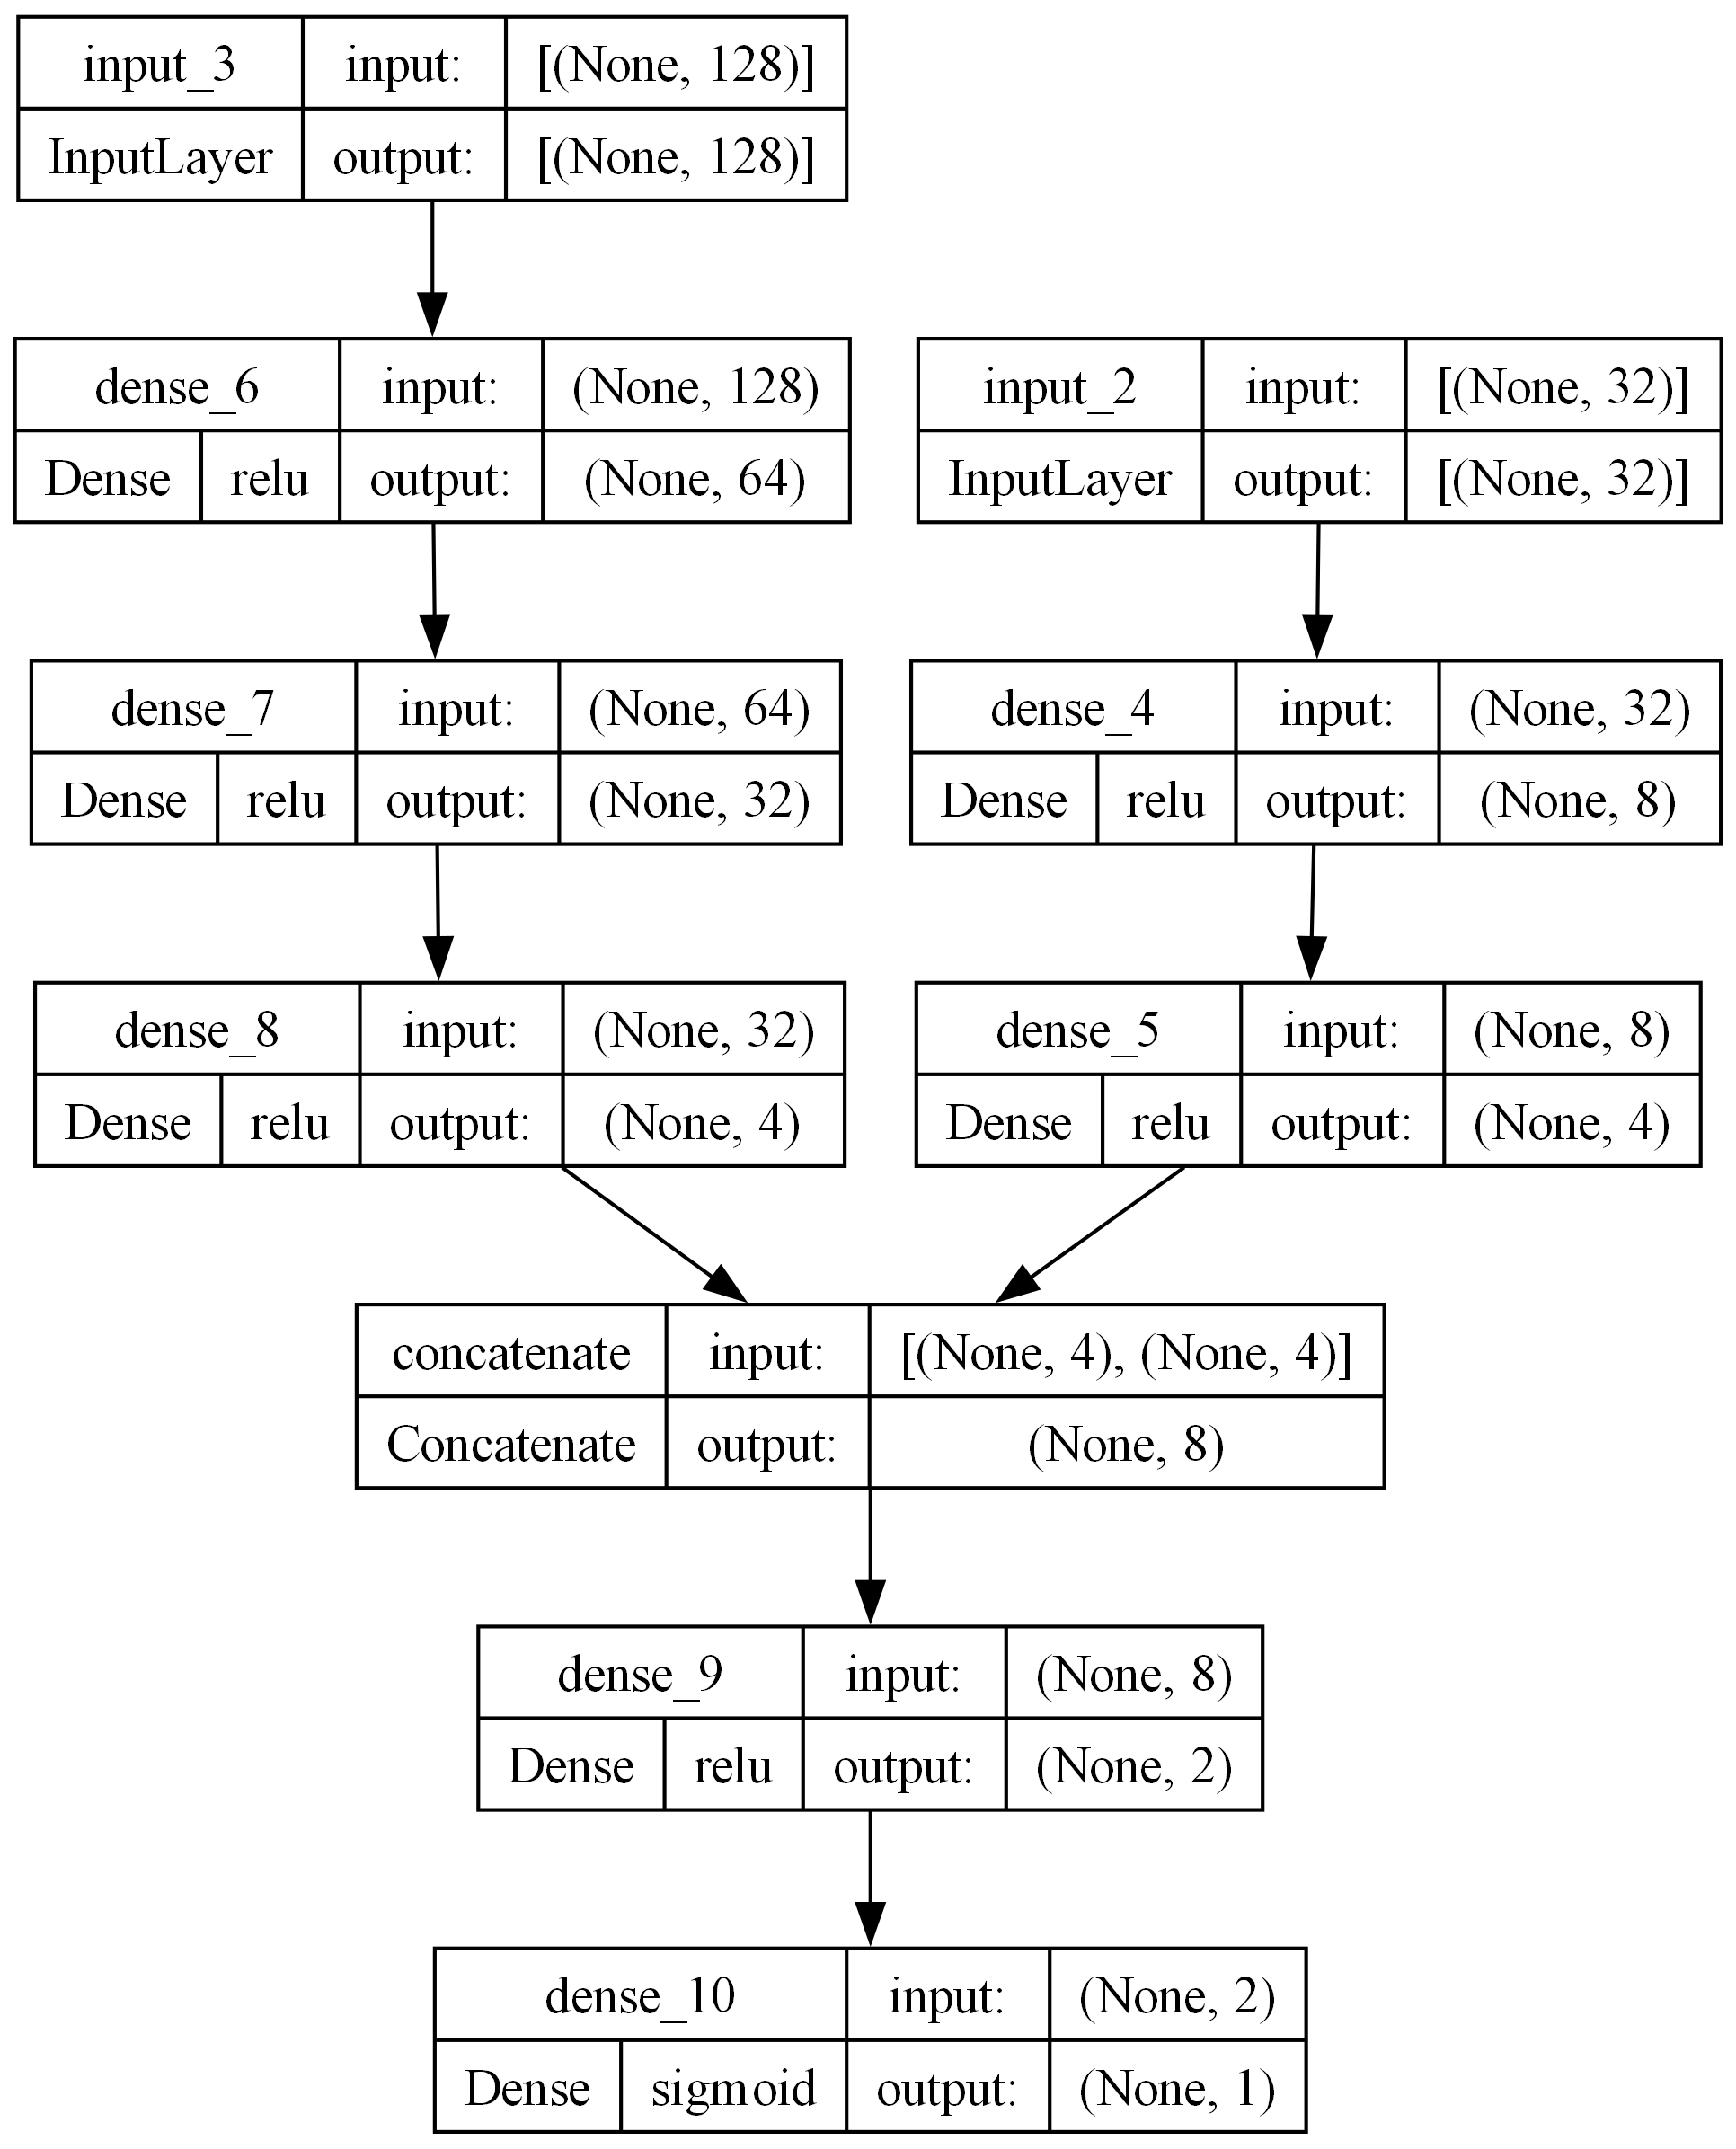

In [ ]:
plot_model(model,show_shapes=True,to_file= f'{curr_dir}/Dataset/output_images/two_input_architecture.png', show_layer_names=True, show_layer_activations=True, rankdir='TB', expand_nested=True, dpi = 100)

# Age Gender Traning

In [13]:
# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("jangedoo/utkface-new", output_dir = f'{curr_dir}/Dataset/UTK') 

# print("Path to dataset files:", path)

In [14]:
# import zipfile
# zip = zipfile.ZipFile(f'{curr_dir}/Dataset/UTK/utkface-new.zip','r')
# zip.extractall("/content")
# zip.close()

In [15]:
import os
import numpy as np
import pandas as pd
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [16]:
folder_path = rf'{curr_dir}\Dataset\UTK\UTKFace'

In [17]:
age=[]
gender=[]
img_path=[]
for file in os.listdir(folder_path):
  age.append(int(file.split('_')[0]))
  gender.append(int(file.split('_')[1]))
  img_path.append(file)

In [18]:
len(age)

23708

In [19]:
df = pd.DataFrame({'age':age,'gender':gender,'img':img_path})

In [20]:
df.shape

(23708, 3)

In [21]:
df.head()

,age,gender,img
0,100,0,100_0_0_20170112213500903.jpg.chip.jpg
1,100,0,100_0_0_20170112215240346.jpg.chip.jpg
2,100,1,100_1_0_20170110183726390.jpg.chip.jpg
3,100,1,100_1_0_20170112213001988.jpg.chip.jpg
4,100,1,100_1_0_20170112213303693.jpg.chip.jpg


In [22]:
train_df = df.sample(frac=1,random_state=0).iloc[:20000]
test_df = df.sample(frac=1,random_state=0).iloc[20000:]

In [23]:
train_df.shape

(20000, 3)

In [24]:
test_df.shape

(3708, 3)

In [25]:
train_datagen = ImageDataGenerator(rescale=1./255,
                                   rotation_range=30,
                                   width_shift_range=0.2,
                                   height_shift_range=0.2,
                                   shear_range=0.2,
                                   zoom_range=0.2,
                                   horizontal_flip=True)

test_datagen = ImageDataGenerator(rescale=1./255)

In [26]:
train_generator = train_datagen.flow_from_dataframe(train_df,
                                                    directory=folder_path,
                                                    x_col='img',
                                                    y_col=['age','gender'],
                                                    target_size=(200,200),
                                                    class_mode='multi_output')

test_generator = test_datagen.flow_from_dataframe(test_df,
                                                    directory=folder_path,
                                                    x_col='img',
                                                    y_col=['age','gender'],
                                                    target_size=(200,200),
                                                  class_mode='multi_output')

Found 20000 validated image filenames.
Found 3708 validated image filenames.


In [29]:
from tensorflow.keras.applications.resnet50 import ResNet50
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model

In [30]:
resnet = ResNet50(include_top=False, input_shape=(200,200,3))

In [31]:
resnet = ResNet50(include_top=False, input_shape=(200,200,3))

resnet.trainable=False

output = resnet.layers[-1].output

flatten = Flatten()(output)

dense1 = Dense(512, activation='relu')(flatten)
dense2 = Dense(512,activation='relu')(flatten)

dense3 = Dense(512,activation='relu')(dense1)
dense4 = Dense(512,activation='relu')(dense2)

output1 = Dense(1,activation='linear',name='age')(dense3)
output2 = Dense(1,activation='sigmoid',name='gender')(dense4)

In [32]:
model = Model(inputs=resnet.input,outputs=[output1,output2])

In [33]:
model.compile(optimizer='adam', loss={'age': 'mae', 'gender': 'binary_crossentropy'}, metrics={'age': 'mae', 'gender': 'accuracy'},loss_weights={'age':1,'gender':99})

In [34]:
def generator_wrapper(generator):
    for x, y in generator:
        yield x, tuple(y)

train_gen_wrapped = generator_wrapper(train_generator)
test_gen_wrapped = generator_wrapper(test_generator)

model.fit(
    train_gen_wrapped,
    steps_per_epoch=len(train_generator),
    epochs=10,
    validation_data=test_gen_wrapped,
    validation_steps=len(test_generator)
)

Epoch 1/10
625/625 [==============================] - 366s 572ms/step - loss: 101.9842 - age_loss: 15.3639 - gender_loss: 0.8750 - age_mae: 15.3639 - gender_accuracy: 0.5117 - val_loss: 83.8121 - val_age_loss: 15.1911 - val_gender_loss: 0.6931 - val_age_mae: 15.1911 - val_gender_accuracy: 0.5173
Epoch 2/10
625/625 [==============================] - 159s 255ms/step - loss: 83.6190 - age_loss: 15.0056 - gender_loss: 0.6931 - age_mae: 15.0056 - gender_accuracy: 0.5235 - val_loss: 83.3792 - val_age_loss: 14.7902 - val_gender_loss: 0.6928 - val_age_mae: 14.7902 - val_gender_accuracy: 0.5189
Epoch 3/10
625/625 [==============================] - 157s 252ms/step - loss: 83.7594 - age_loss: 14.9049 - gender_loss: 0.6955 - age_mae: 14.9049 - gender_accuracy: 0.5238 - val_loss: 83.2443 - val_age_loss: 14.7195 - val_gender_loss: 0.6922 - val_age_mae: 14.7195 - val_gender_accuracy: 0.5146
Epoch 4/10
625/625 [==============================] - 179s 287ms/step - loss: 83.7474 - age_loss: 14.8074 - gen